In [1]:
import time
import h5py
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')

from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.utils import *
from pathlib import Path
%matplotlib widget 

In [2]:
os.makedirs('proc', exist_ok=True)
os.makedirs('avg', exist_ok=True)
os.makedirs('figs', exist_ok=True)

### create a fim tracking along different channels to see how it is shaped and how it changes
- I believe that fim0 and fim1 are connected, so i pair up each channels fim0 and fim1

In [3]:
import numpy as np


def integrate_fim_pair(
    wf0,
    wf1,
    channels,
    roi,
    bg_roi,
    threshold=0.0,
    polarity="negative",
    return_mask=False,
):
    """
    Background-subtract, integrate, and cross-mask a pair of FIM waveforms.

    Pipeline (per the requested logic):
      1. Estimate a per-shot, per-channel baseline from `bg_roi` and subtract it.
      2. Integrate the baseline-subtracted trace over `roi` -> one value per
         (shot, channel).
      3/4. Flag (shot, channel) entries that are "the wrong sign" in EITHER
         waveform. The union of the two masks is exactly the deduped set of
         coordinates ("keep one if repeated"), so a coordinate flagged by
         either monitor is handled once.
      5. Zero those entries in BOTH integrated matrices and return them.

    Parameters
    ----------
    wf0, wf1 : array_like
        Raw waveforms, shape (n_shots, n_channels, n_samples). The third axis
        is the sample/time axis that `roi` and `bg_roi` index into.
    channels : sequence of int
        Channel indices of interest. The output channel axis follows this
        order, so the result has shape (n_shots, len(channels)).
    roi : slice | tuple(int, int) | sequence of int
        Integration window on the sample axis. A 2-tuple is read as
        (start, stop); a list/array is read as explicit sample indices.
    bg_roi : slice | tuple(int, int) | sequence of int
        Window used to estimate the baseline (same conventions as `roi`).
    threshold : float, default 0.0
        Non-negative detection depth. An entry is kept only if it is more
        extreme than `threshold` in the signal direction; otherwise it is
        zeroed. At threshold=0 this reduces exactly to "zero the positive
        values" (for negative polarity). Raising it also discards weak
        same-sign noise near zero.
    polarity : {"negative", "positive"}, default "negative"
        Polarity of the *real* signal.
          - "negative": genuine pulses integrate negative; keep integ < -threshold,
            zero everything else. (At threshold=0 this zeros all positives.)
          - "positive": genuine pulses integrate positive; keep integ > threshold,
            zero everything else.
    return_mask : bool, default False
        If True, also return the boolean (n_shots, len(channels)) mask of
        entries that were zeroed.

    Returns
    -------
    integ0, integ1 : np.ndarray
        Integrated, cross-masked intensities, shape (n_shots, len(channels)).
    mask : np.ndarray, optional
        Only if `return_mask=True`. True where the entry was zeroed in both.
    """
    wf0 = np.asarray(wf0, dtype=float)
    wf1 = np.asarray(wf1, dtype=float)
    if wf0.shape != wf1.shape:
        raise ValueError(f"wf0 {wf0.shape} and wf1 {wf1.shape} must have the same shape.")
    if wf0.ndim != 3:
        raise ValueError(f"expected (shots, channels, samples); got {wf0.shape}")

    def _to_index(r):
        if isinstance(r, slice):
            return r
        if isinstance(r, tuple) and len(r) == 2:
            return slice(int(r[0]), int(r[1]))
        return np.asarray(r)  # explicit list/array of sample indices

    ch = np.asarray(channels)
    roi_idx = _to_index(roi)
    bg_idx = _to_index(bg_roi)

    def _integrate(wf):
        sub = wf[:, ch, :]                                  # (shots, n_ch, samples)
        baseline = sub[:, :, bg_idx].mean(axis=-1, keepdims=True)
        sub = sub - baseline                                # per-shot, per-channel bg subtraction
        return sub[:, :, roi_idx].sum(axis=-1)              # (shots, n_ch)

    integ0 = _integrate(wf0)
    integ1 = _integrate(wf1)

    # steps 3 & 4: flag entries that are NOT real signal in either waveform
    # (union of the two masks = the deduped coordinate set, "keep one if repeated")
    if polarity == "negative":
        to_zero = (integ0 > -threshold) | (integ1 > -threshold)
    elif polarity == "positive":
        to_zero = (integ0 < threshold) | (integ1 < threshold)
    else:
        raise ValueError("polarity must be 'negative' or 'positive'")

    # step 5: zero those entries in BOTH matrices
    integ0[to_zero] = 0.0
    integ1[to_zero] = 0.0

    if return_mask:
        return integ0, integ1, to_zero
    return integ0, integ1

In [3]:
import yaml
# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 140
fyaml_path = '../roi_input.yml'         # swap to ferufe/roi_input_ferufe.yml if needed
n_show     = -1                       # subsample for speed
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'

with open(fyaml_path) as f:
    cfg = yaml.safe_load(f)
    fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']

with h5py.File(fname, 'r') as h5:
    fim0_wf = h5['intg']['axis_svls']['det_rix_fim0_sum_full_area'][:n_show]
    fim1_wf = h5['intg']['axis_svls']['det_rix_fim1_sum_full_area'][:n_show]
    apd_wf = h5['intg']['axis_svls']['det_crix_w8_sum_full_area'][:n_show]
    
integ0, integ1 = integrate_fim_pair(fim0_wf, fim1_wf,
                                    channels=fim0_cfg['channels'],  # same channels for both
                                    roi=(65,75),          # same roi for both
                                    bg_roi=(0,60),    # same bg_roi for both
                                    threshold=1000,                # keep all same-sign entries
                                    polarity='negative',          # signal is negative-going
                                    return_mask=False)

print(f'integ0 shape: {integ0.shape}, integ1 shape: {integ1.shape}')

fig, ax = plt.subplots(8, 2, figsize=(8, 30))
for i, c in enumerate(fim0_cfg['channels']):
    ax[i, 0].hist(integ0[:, i], bins=120); ax[i, 0].set_title(f'fim0 ch{c} integrated')
    ax[i, 1].hist(integ1[:, i], bins=120); ax[i, 1].set_title(f'fim1 ch{c} integrated')
    
print("Seems like the channels 4, 5, 6, 7 have good signal")

# Plot out the scatter plots for each integrated channel
fig1, ax1 = plt.subplots(8, 1, figsize=(8, 40))
for i, c in enumerate(fim0_cfg['channels']):
    ax1[i].scatter(integ0[:, i], integ1[:, i], alpha=0.5, s=10)
    ax1[i].set_xlabel(f'fim0 ch{c} integrated')
    ax1[i].set_ylabel(f'fim1 ch{c} integrated')
    ax1[i].set_title(f'fim0 vs. fim1 integrated intensities, ch{c}')
    
print('Channel 4 definitely has the best linear fit')


NameError: name 'integrate_fim_pair' is not defined

### Function for automatically determining the fim ROIs

In [4]:
"""
Automatic ROI finder for FIM diode waveforms (finalized).

Input
-----
fim_wf : np.ndarray
    (shots, channels, samples)  multi-channel  (averaged over shots), or
    (shots, samples)            one channel     (averaged over shots), or
    (samples,)                  one already-averaged template.
    The LAST axis is always the time/sample axis.

Per channel, the function:
  1. Builds a high-SNR template by averaging over shots.
  2. Auto-detects the BACKGROUND ROI: the flat region at the left edge, ending
     a few samples BEFORE the signal first departs from baseline (so no real
     signal leaks into the background).
  3. Subtracts the background mean from the template.
  4. Identifies the FIRST oscillation after the background: the first
     significant zero-crossing-bounded excursion (0 -> peak -> 0), of EITHER
     sign. This first oscillation must be NEGATIVE -- if it is positive the
     channel is rejected with signal ROI = [0.0, 0.0]. If it is negative and
     contains the most-negative sample of the trace, the SIGNAL ROI is that
     oscillation traced to its bounding zero crossings (sub-sample, rounded to
     0.1). Otherwise the channel is rejected with [0.0, 0.0].

Returns
-------
bg_rois     : list of [start, end] background windows, one per channel.
signal_rois : list of [start, end] signal windows, one per channel
              ([0.0, 0.0] when the first oscillation is not the deepest).
"""

import warnings

import numpy as np


def _first_sustained(mask, run=2):
    """First index where `mask` is True for `run` consecutive samples."""
    if run <= 1:
        idx = np.flatnonzero(mask)
        return int(idx[0]) if idx.size else None
    win = np.convolve(mask.astype(int), np.ones(run, int), mode="valid")
    hit = np.flatnonzero(win == run)
    return int(hit[0]) if hit.size else None


def _zero_between(y, a, b):
    """Linearly interpolated zero crossing between samples a and b."""
    ya, yb = float(y[a]), float(y[b])
    if yb == ya:
        return float(a)
    return a + (-ya) / (yb - ya)


def _despike(y, w=3, spike_frac=0.2):
    """Replace only genuine outlier samples; leave everything else untouched.

    A median-filtered copy erases 1-2 sample glitches. A sample is judged an
    outlier only if it sits more than `spike_frac` of the signal scale away from
    that local median, and ONLY those samples are overwritten. Baseline noise and
    the real (smooth, multi-sample) dip are left exactly as-is, so ROI edges do
    not move on clean channels -- unlike a plain median smooth, which shifts them."""
    w = int(w)
    if w < 3:
        return y
    if w % 2 == 0:
        w += 1
    pad = w // 2
    yp = np.pad(y, pad, mode="edge")
    med = np.median(np.lib.stride_tricks.sliding_window_view(yp, w), axis=1)
    scale = float(np.max(np.abs(med - np.median(med)))) or 1.0   # signal scale (spike-free)
    out = y.copy()
    spikes = np.abs(y - med) > spike_frac * scale
    out[spikes] = med[spikes]
    return out


def _channel_rois(trace, w_var=8, var_factor=5.0, k=5.0, bg_margin=3,
                  onset_frac=0.05, min_width=2, accept_frac=0.0, skip_start=0,
                  despike=3):
    """Background ROI + signal ROI + reason for one channel's averaged trace."""
    trace = np.asarray(trace, dtype=float)
    n = trace.size
    finite = np.isfinite(trace)
    if not finite.any():                   # dead / all-NaN channel
        return [0.0, float(n - 1)], [0.0, 0.0], "dead_channel"
    if not finite.all():                   # residual NaNs (a sample NaN in ALL
        trace = trace.copy()               # shots): fill so argmin can't latch
        trace[~finite] = np.median(trace[finite])   # onto a NaN

    # Median-despike: erase 1-2 sample outliers before any shape analysis so a
    # lone glitch cannot inflate the signal scale, split the dip into two lobes,
    # or become a false deepest point. Only affects ROI boundary detection.
    trace = _despike(trace, despike)

    # ---- 2. background ROI via a sliding-window LOCAL-VARIANCE scan ----
    # Scan left to right measuring the local standard deviation in a window of
    # `w_var` samples. The baseline is flat (low, steady local std); the signal
    # makes the local std jump. The background ends at the first jump (minus a
    # margin). This lets the baseline define itself from its own flatness instead
    # of trusting a fixed seed of the first N samples.
    skip_start = int(min(max(0, skip_start), max(0, n - w_var - 1)))
    h = max(1, int(w_var) // 2)
    win = np.lib.stride_tricks.sliding_window_view(np.pad(trace, h, mode="edge"),
                                                   2 * h + 1)
    rstd = win.std(axis=1)[:n]             # centered local std, one per sample

    valid = rstd[skip_start:]
    base_level = float(np.percentile(valid, 25)) or 1e-12   # robust baseline noise std
    peak_var = float(valid.max()) or 1e-12                  # signal variance scale
    # a jump counts only if it clears BOTH the baseline-noise floor AND a
    # fraction of the signal's own variance (so small bumps stay background).
    thr_var = max(var_factor * base_level, onset_frac * peak_var)

    over = np.flatnonzero(rstd > thr_var)
    over = over[over >= skip_start]
    if over.size == 0:                     # never leaves baseline -> no signal
        return [float(skip_start), float(n - 1)], [0.0, 0.0], "no_onset"
    onset = int(over[0])
    bg_end = max(onset - bg_margin, skip_start + 1)
    bg_roi = [float(skip_start), float(bg_end)]

    # ---- 3. subtract the background level (MEDIAN of the background ROI) ----
    # Median, not mean: a small bump sitting inside the background window would
    # skew the mean and lift the baseline, making the post-bump region read
    # negative and merge into the dip. The median ignores such a localized bump.
    bg_level = float(np.median(trace[skip_start:bg_end]))
    y = trace - bg_level
    sigma_bg = float(trace[skip_start:bg_end].std()) or 1e-12
    peak = float(np.max(np.abs(y[skip_start:])))           # amplitude signal scale
    sig_thr = max(k * sigma_bg, onset_frac * peak)   # floor for lobe significance

    # ---- 4. first oscillation after background = first SIGNIFICANT lobe ----
    # An oscillation is one zero-crossing-bounded excursion (0 -> peak -> 0).
    # Collect significant lobes of EITHER sign, so a leading POSITIVE excursion
    # is seen and rejected rather than silently skipped. Lobes narrower than
    # `min_width` are dropped: a single-sample spike is a glitch, not an
    # oscillation, and must not be allowed to count as the deepest feature.
    cross = np.flatnonzero(y[:-1] * y[1:] < 0) + 1
    bounds = np.concatenate(([0], cross, [n])).astype(int)
    lobes = []                              # (start, end, peak_idx, sign)
    for bi in range(len(bounds) - 1):
        s, e = int(bounds[bi]), int(bounds[bi + 1]) - 1
        if e < s or e < bg_end:             # skip anything inside the background
            continue
        if (e - s + 1) < min_width:         # skip single-sample spikes / glitches
            continue
        pk = s + int(np.argmax(np.abs(y[s:e + 1])))
        if abs(y[pk]) > sig_thr:            # significant excursion (either sign)
            lobes.append((s, e, pk, int(np.sign(y[pk]))))

    if not lobes:
        return bg_roi, [0.0, 0.0], "no_significant_lobe"

    s0, e0, pk0, sign0 = lobes[0]           # THE first oscillation

    # the first oscillation MUST be negative; a positive first lobe -> reject
    if sign0 > 0:
        return bg_roi, [0.0, 0.0], f"first_oscillation_positive(peak@{pk0})"

    # Accept the first oscillation as the signal. By default (accept_frac=0.0)
    # a deeper-but-later lobe -- ringing, a reflection, or a stray deep sample
    # -- does NOT veto it. Set accept_frac > 0 to require the first oscillation
    # to be at least that fraction as deep as the deepest negative lobe.
    depth_first = abs(y[pk0])
    depth_deepest = max(abs(y[pk]) for (s, e, pk, sg) in lobes if sg < 0)
    if depth_first < accept_frac * depth_deepest:
        return (bg_roi, [0.0, 0.0],
                f"first_oscillation_too_shallow({depth_first / depth_deepest:.2f}"
                f"<{accept_frac})")

    # trace the first oscillation out to its bounding zero crossings (sub-sample)
    left = _zero_between(y, s0 - 1, s0) if s0 > 0 else 0.0
    right = _zero_between(y, e0, e0 + 1) if e0 < n - 1 else float(e0)
    return bg_roi, [round(left, 1), round(right, 1)], "ok"


def find_fim_rois(fim_wf, w_var=8, var_factor=5.0, k=5.0, bg_margin=3,
                  onset_frac=0.05, min_width=2, accept_frac=0.0, skip_start=0,
                  despike=3, verbose=True, return_reasons=False):
    """Auto-find background and signal ROIs for every FIM channel.

    Parameters
    ----------
    fim_wf    : waveforms. Accepted shapes:
                  (shots, channels, samples) -> multi-channel, averaged over shots
                  (shots, samples)           -> ONE channel, averaged over shots
                  (samples,)                 -> one already-averaged template
                The LAST axis must always be the time/sample axis.
    w_var     : sliding-window width for the local-variance baseline scan.
    var_factor: local std must exceed var_factor * baseline std to count as the
                signal onset (works together with onset_frac).
    k         : lobe-significance threshold in units of background sigma.
    bg_margin : samples to back off before the onset when closing the background.
    onset_frac: a feature must also reach this fraction of the signal scale to
                count -- keeps small bumps in the background.
    despike   : median-despike width (3 removes 1-sample glitches, 5 two-sample).
    skip_start: samples of startup to ignore before scanning.

    Returns
    -------
    bg_rois, signal_rois : two lists of [start, end], one entry per channel.
    """
    fim_wf = np.asarray(fim_wf, dtype=float)
    if fim_wf.ndim == 1:                        # (samples,) -> one template
        fim_wf = fim_wf[None, None, :]
    elif fim_wf.ndim == 2:                      # (shots, samples) -> one channel
        fim_wf = fim_wf[:, None, :]
    elif fim_wf.ndim != 3:                      # expect (shots, channels, samples)
        raise ValueError(f"fim_wf must be 1-3 dimensional, got {fim_wf.ndim}D.")

    # Average over shots IGNORING NaNs. With a plain mean, a single NaN shot
    # makes the whole channel-average NaN, np.argmin then lands on the NaN, and
    # the channel is silently rejected as [0.0, 0.0].
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN channels
        template = np.nanmean(fim_wf, axis=0)             # (channels, samples)

    n_channels, n_samples = template.shape
    if n_samples < max(4, 2 * w_var):
        raise ValueError(
            f"Each waveform has only {n_samples} sample(s) on the last axis, which "
            f"is too short to find an oscillation. The LAST axis must be the "
            f"time/sample axis. For a single-channel (shots, samples) array, pass "
            f"it directly or use wf[:, None, :] -- NOT wf[:, :, None].")

    bg_rois, signal_rois, reasons = [], [], []
    for ch in range(n_channels):
        bg, sig, reason = _channel_rois(template[ch], w_var=w_var, var_factor=var_factor,
                                        k=k, bg_margin=bg_margin, onset_frac=onset_frac,
                                        min_width=min_width, accept_frac=accept_frac,
                                        skip_start=skip_start, despike=despike)
        bg_rois.append(bg)
        signal_rois.append(sig)
        reasons.append(reason)
        if verbose:
            tag = "ok" if reason == "ok" else f"REJECT ({reason})"
            print(f"ch{ch}: bg={bg}  signal={sig}  [{tag}]")
    if return_reasons:
        return bg_rois, signal_rois, reasons
    return bg_rois, signal_rois

In [4]:
import yaml
# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 13
fyaml_path = '../roi_input.yml'         # swap to ferufe/roi_input_ferufe.yml if needed
n_show     = -1                       # subsample for speed
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'

with open(fyaml_path) as f:
    cfg = yaml.safe_load(f)
    fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']
    apd_cfg = cfg['apd']

with h5py.File(fname, 'r') as h5:
    # fim0_wf = h5['intg']['axis_svls']['det_rix_fim0_sum_full_area'][:n_show]
   #  fim1_wf = h5['intg']['axis_svls']['det_rix_fim1_sum_full_area'][:n_show]
    apd_wf = h5['intg']['axis_svls']['det_crix_w8_sum_full_area'][:n_show]
    
# background_roi_0, signal_roi_0 = find_fim_rois(fim0_wf)
# background_roi_1, signal_roi_1 = find_fim_rois(fim1_wf)

apd_bg_roi, apd_sig_roi = find_fim_rois(apd_wf)



print(f'background: {apd_bg_roi},   signal: {apd_sig_roi}')
# plot the integrated ROIS to see if they match with the waveform 



ch0: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch1: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch2: bg=[0.0, 134.0]  signal=[143.3, 159.7]  [ok]
ch3: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch4: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch5: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch6: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch7: bg=[0.0, 52.0]  signal=[0.0, 0.0]  [REJECT (first_oscillation_positive(peak@57))]
background: [[0.0, 255.0], [0.0, 255.0], [0.0, 134.0], [0.0, 255.0], [0.0, 255.0], [0.0, 255.0], [0.0, 255.0], [0.0, 52.0]],   signal: [[0.0, 0.0], [0.0, 0.0], [143.3, 159.7], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]


In [12]:
# track roi changes across runs per channel
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'

fyaml_path = '../roi_input.yml'         # swap to ferufe/roi_input_ferufe.yml if needed
n_show     = -1      # subsample for speed

# runs = [112, 114, 115, 120, 123, 129, 138, 140, 141, 155, 180, 226, 230, 241, 250]
runs = [13,194]
roi_0_vs_runs = []
roi_1_vs_runs = []
apd_vs_runs = []

for i in runs:
    fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{i:04d}.h5'
    
    with open(fyaml_path) as f:
        cfg = yaml.safe_load(f)
        # fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']
        apd_cfg = cfg['apd']
    
    with h5py.File(fname, 'r') as h5:
        fim0_wf = h5['intg']['axis_svls']['det_rix_fim0_sum_full_area'][:n_show]
        # fim1_wf = h5['intg']['axis_svls']['det_rix_fim1_sum_full_area'][:n_show]
        #apd_wf = h5['intg']['axis_svls']['det_crix_w8_sum_full_area'][:n_show]
        
        find_fim_rois(fim0_wf)
        
    # background_roi_0, signal_roi_0 = find_fim_rois(fim0_wf)
    # background_roi_1, signal_roi_1 = find_fim_rois(fim1_wf)
    fim0_bg_roi, fim0_sig_roi = find_fim_rois(fim0_wf)
    
    # roi_0_vs_runs.append(signal_roi_0)
    # roi_1_vs_runs.append(signal_roi_1)
    apd_vs_runs.append(fim0_sig_roi)
    


    


ch0: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch1: bg=[0.0, 61.0]  signal=[0.0, 0.0]  [REJECT (first_oscillation_positive(peak@69))]
ch2: bg=[0.0, 62.0]  signal=[68.2, 72.2]  [ok]
ch3: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch4: bg=[0.0, 61.0]  signal=[66.0, 72.8]  [ok]
ch5: bg=[0.0, 61.0]  signal=[65.2, 73.1]  [ok]
ch6: bg=[0.0, 62.0]  signal=[66.0, 71.3]  [ok]
ch7: bg=[0.0, 62.0]  signal=[0.0, 0.0]  [REJECT (first_oscillation_positive(peak@69))]
ch0: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch1: bg=[0.0, 61.0]  signal=[0.0, 0.0]  [REJECT (first_oscillation_positive(peak@69))]
ch2: bg=[0.0, 62.0]  signal=[68.2, 72.2]  [ok]
ch3: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch4: bg=[0.0, 61.0]  signal=[66.0, 72.8]  [ok]
ch5: bg=[0.0, 61.0]  signal=[65.2, 73.1]  [ok]
ch6: bg=[0.0, 62.0]  signal=[66.0, 71.3]  [ok]
ch7: bg=[0.0, 62.0]  signal=[0.0, 0.0]  [REJECT (first_oscillation_positive(peak@69))]
ch0: bg=[0.0, 255.0]  signal=[0.

[[143.3 159.7]
 [143.2 159.7]]


/lscratch/jwang343/tmp/ipykernel_2521964/397708911.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


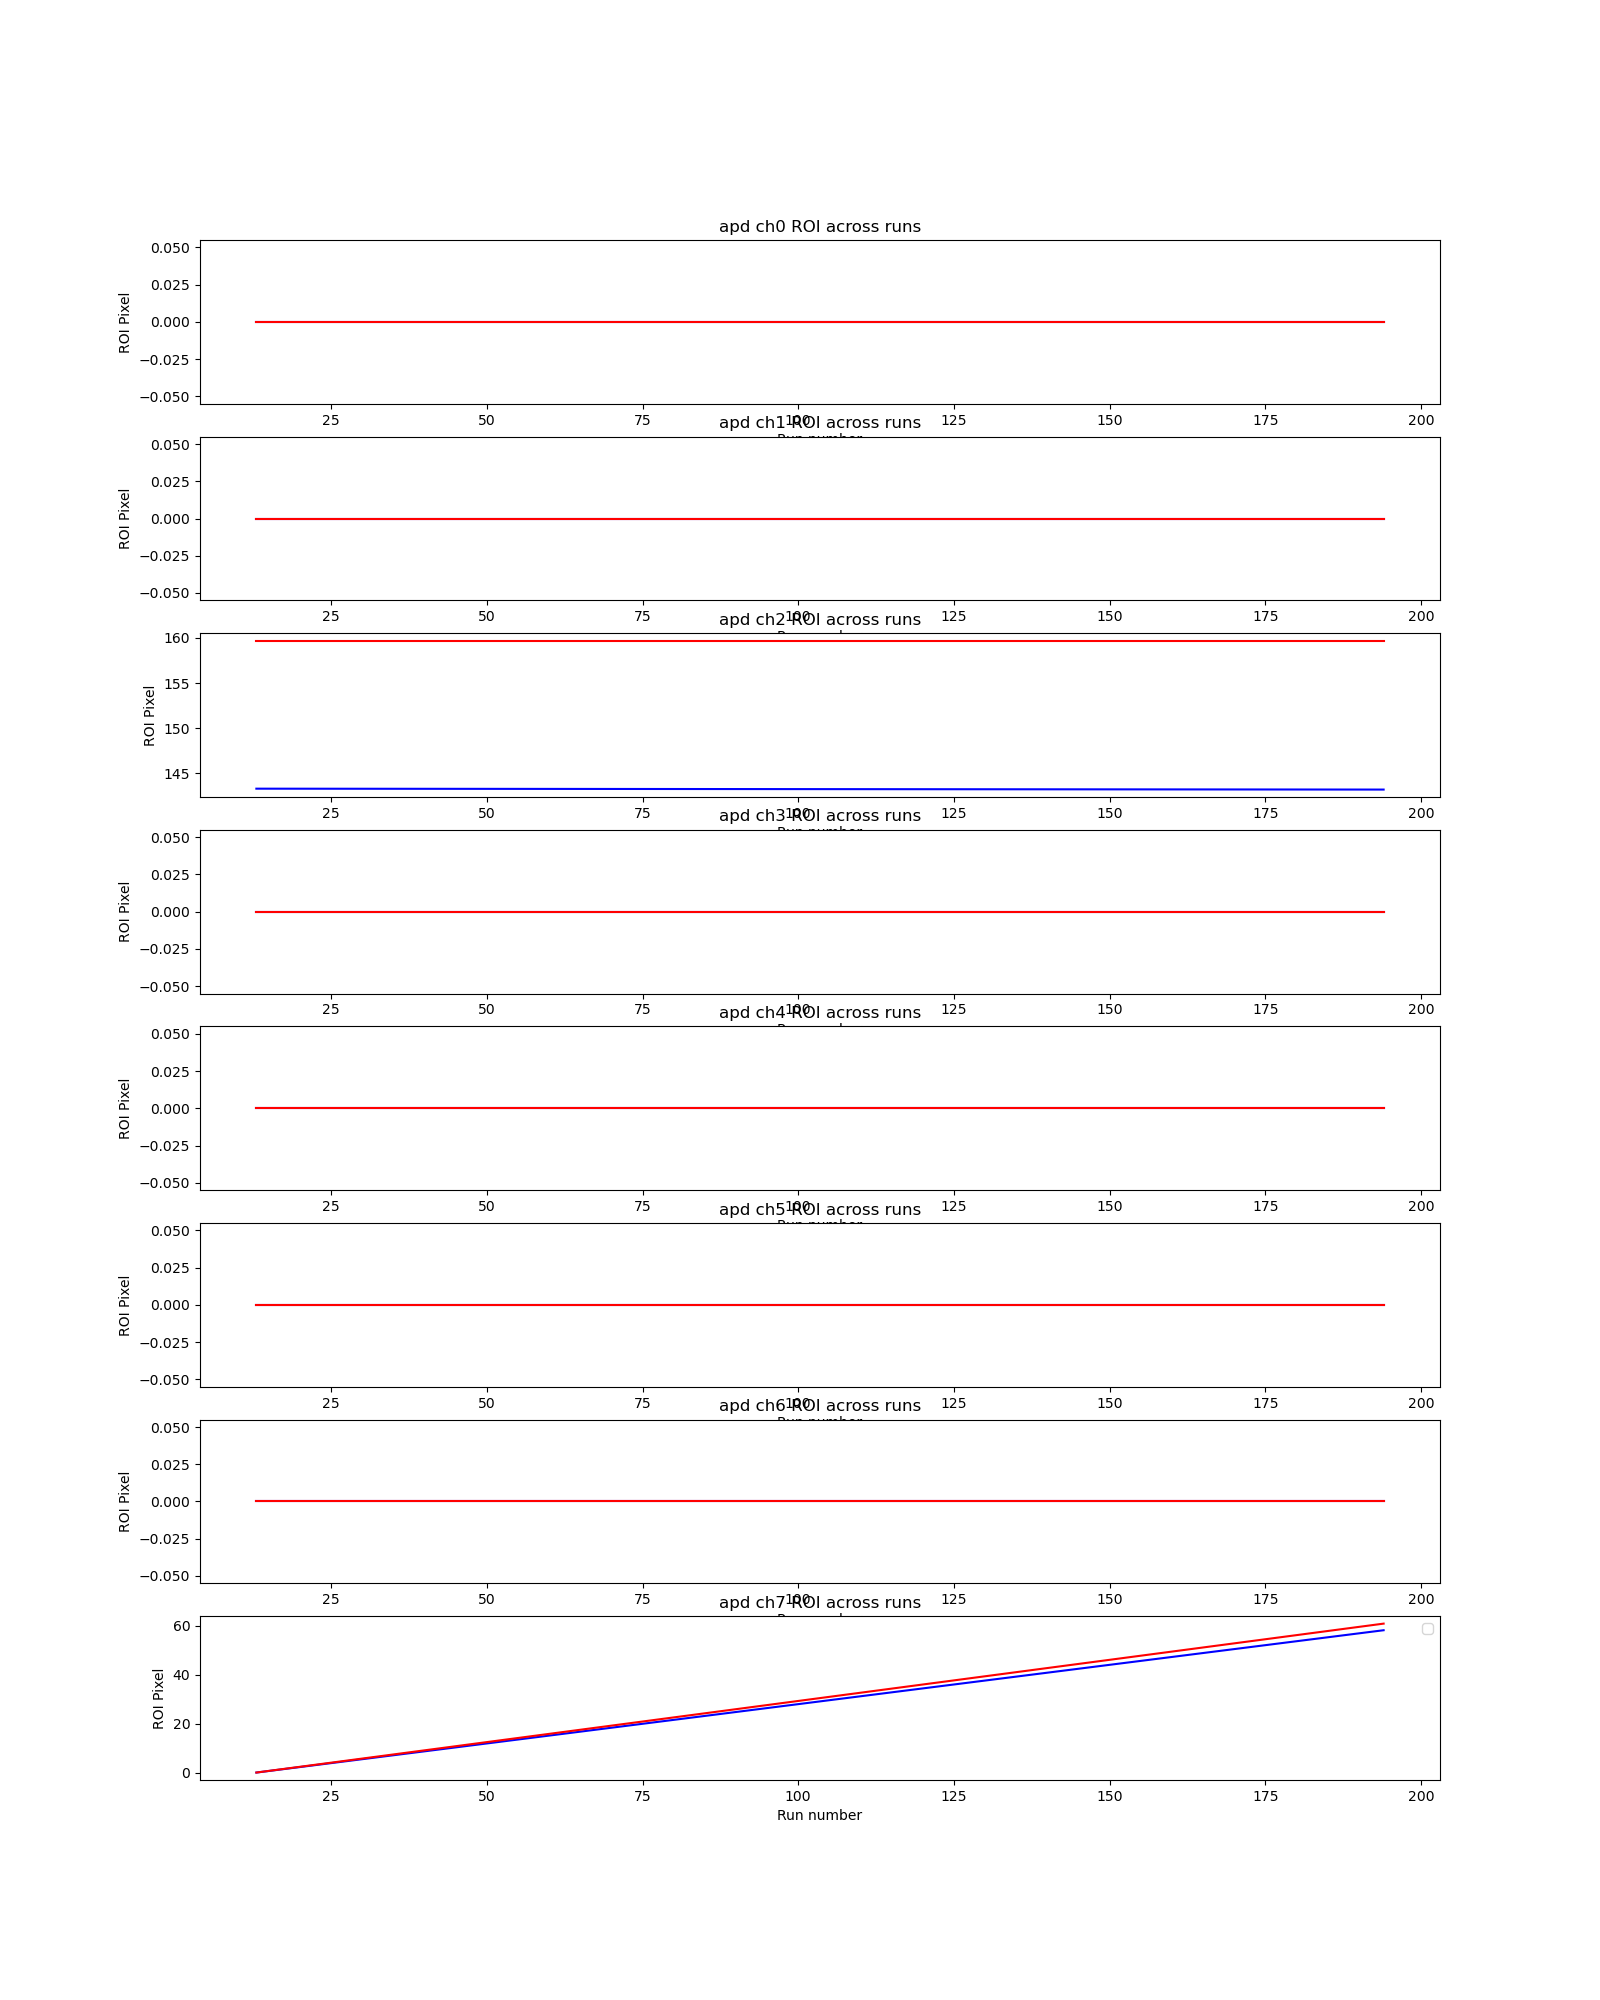

In [6]:
# roi_0_vs_runs_np = np.asarray(roi_0_vs_runs)  
# roi_1_vs_runs_np = np.asarray(roi_1_vs_runs)
apd_vs_runs_np = np.asarray(apd_vs_runs)

print(apd_vs_runs_np[:,2,:])

# roi_0_vs_runs_swap = np.swapaxes(roi_0_vs_runs_np, 0, 1)# (channels, runs, 2) -> easier to plot per channel
# roi_1_vs_runs_swap = np.swapaxes(roi_1_vs_runs_np, 0, 1)# (channels, runs, 2) -> easier to plot per channel
apd_vs_runs_swap = np.swapaxes(apd_vs_runs_np, 0, 1)



fig, ax = plt.subplots(8, 1, figsize=(16, 20))
for i, c in enumerate([0,1,2,3,4,5,6,7]):
    ax[i].plot(runs, apd_vs_runs_swap[i, :, 0], 'b')
    ax[i].plot(runs, apd_vs_runs_swap[i, :, 1], 'r')
    ax[i].set_title(f'apd ch{c} ROI across runs')
    ax[i].set_xlabel('Run number')
    ax[i].set_ylabel('ROI Pixel')
    plt.legend()


# fig, ax = plt.subplots(8, 2, figsize=(16, 50))
# ax[0][0].set_title('fim0 ROIs across runs'); ax[0][1].set_title('fim1 ROIs across runs')
# for i, c in enumerate(fim0_cfg['channels']):
#     ax[i][0].plot(runs, roi_0_vs_runs_swap[i, :, 0], 'b')
#     ax[i][0].plot(runs, roi_0_vs_runs_swap[i, :, 1], 'r')
#     ax[i][0].set_title(f'fim0 ch{c} ROI across runs')
#     ax[i][0].set_xlabel('Run number')
#     ax[i][0].set_ylabel('ROI Pixel')
#     ax[i][1].plot(runs, roi_1_vs_runs_swap[i, :, 0], 'b')
#     ax[i][1].plot(runs, roi_1_vs_runs_swap[i, :, 1], 'r')
#     ax[i][1].set_title(f'fim1 ch{c} ROI across runs')
#     ax[i][1].set_xlabel('Run number')
#     ax[i][1].set_ylabel('ROI Pixel')
#     plt.legend()

In [ ]:
# 

In [ ]:
"""Minimal FIM plotter: highlights ONLY the signal ROI, nothing else."""
import numpy as np
import matplotlib.pyplot as plt


def plot_fim_roi_only(wf, channels, rois, det_name="fim",
                      n_shots_show=30, color="red", alpha=0.30,
                      ncols=8, seed=0, run_num = 0):
    """Plot each FIM channel's waveform with only the signal ROI shaded.

    Parameters
    ----------
    wf        : (shots, channels, samples) raw waveforms, or a
                (channels, samples) shot-averaged template.
    channels  : 1-indexed channel numbers (as in your YAML config).
    rois      : list of [start, end] per channel, same order as `channels`
                (e.g. the `rois_0` / `rois_1` returned by find_fim_rois).
    det_name  : label for subplot titles ('fim0' / 'fim1').
    n_shots_show : faint individual shots to overlay (0 to disable).

    Only the ROI span is highlighted -- no bg_roi, no peak lines.
    """
    rng = np.random.default_rng(seed)
    template = wf.mean(0) if wf.ndim == 3 else wf
    nsamp = template.shape[-1]
    x = np.arange(nsamp)

    n = len(channels)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 3 * nrows),
                             sharex=True, squeeze=False)
    axes = axes.flat
    fig.suptitle(f'Fims from run {run_num}')

    for i, c in enumerate(channels):
        ax = axes[i]
        ch = c - 1                                   # YAML is 1-indexed
        if wf.ndim == 3 and n_shots_show:
            k = min(n_shots_show, wf.shape[0])
            for j in rng.choice(wf.shape[0], k, replace=False):
                ax.plot(x, wf[j, ch, :], color="steelblue", alpha=0.1, lw=0.5)
        ax.plot(x, template[ch], "k", lw=1.2)
        # s, e = rois[i]
        # ax.axvspan(s, e, color=color, alpha=alpha)   # <-- ONLY the ROI
        ax.set_title(f"{det_name} ch{c}", fontsize=9)
        ax.set_xlabel("sample")

    for j in range(n, len(axes)):                    # hide any empty cells
        axes[j].axis("off")

    plt.tight_layout()
    return fig


runs = [120, 145, 248]
solid_runs = [13,194]
all_runs = list(np.linspace(11, 252, 252-11+1).astype(int))
first_50 = all_runs[112:120]
second_50 = all_runs[100:150]

for i in first_50:
    fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{i:04d}.h5'
    
    with open(fyaml_path) as f:
        cfg = yaml.safe_load(f)
        # fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']
        apd_cfg = cfg['apd']
    
    with h5py.File(fname, 'r') as h5:
        # fim0_wf = h5['intg']['axis_svls']['det_rix_fim0_sum_full_area'][:n_show]
        # fim1_wf = h5['intg']['axis_svls']['det_rix_fim1_sum_full_area'][:n_show]
        apd_wf = h5['intg']['axis_svls']['det_crix_w8_sum_full_area'][:n_show]
        
    # background_roi_0, signal_roi_0 = find_fim_rois(fim0_wf)
    # background_roi_1, signal_roi_1 = find_fim_rois(fim1_wf)
    background_roi_apd, signal_roi_apd = find_fim_rois(apd_wf)
    
    
    # plot_fim_roi_only(fim0_wf, fim0_cfg['channels'], signal_roi_0, det_name="fim0", run_num = i)
    # plot_fim_roi_only(fim1_wf, fim1_cfg['channels'], signal_roi_1, det_name="fim1", run_num = i)
    plot_fim_roi_only(apd_wf, apd_cfg['channels'], signal_roi_apd, det_name="apd", run_num = i)

ch0: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch1: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch2: bg=[0.0, 53.0]  signal=[0.0, 0.0]  [REJECT (first_oscillation_positive(peak@59))]
ch3: bg=[0.0, 49.0]  signal=[0.0, 0.0]  [REJECT (first_oscillation_positive(peak@62))]
ch4: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch5: bg=[0.0, 255.0]  signal=[0.0, 0.0]  [REJECT (no_onset)]
ch6: bg=[0.0, 58.0]  signal=[61.7, 129.8]  [ok]
ch7: bg=[0.0, 51.0]  signal=[53.4, 68.9]  [ok]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import h5py

def _make_apd_fig(avg, run_num, bg_range=(0, 25), time_axis=None, title=None, ncols=8):

    fig_title = title or f"Run {run_num} — APD avg waveforms"

    if avg is None:
        fig, ax = plt.subplots(figsize=(18, 3.5))
        ax.axis('off')
        ax.text(0.5, 0.5, "No waveform data available",
                ha='center', va='center', fontsize=11,
                color='gray', transform=ax.transAxes)
        fig.suptitle(fig_title, fontsize=13)
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        return fig

    n_channels, n_samples = avg.shape
    s, e = int(bg_range[0]), int(bg_range[1])

    avg_sub = avg - np.median(avg[:, s:e], axis=1, keepdims=True)

    x = time_axis if time_axis is not None else np.arange(n_samples)
    xlabel = "Time" if time_axis is not None else "Sample index"

    ncols = min(ncols, n_channels)
    nrows = int(np.ceil(n_channels / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.5 * ncols, 3 * nrows),
                             sharex=True, squeeze=False)
    axes = axes.flat

    fig.suptitle(fig_title, fontsize=13)

    for i in range(n_channels):
        ax = axes[i]
        ax.plot(x, avg_sub[i], color='black', linewidth=1.2)
        ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
        ax.set_title(f"apd ch{i}", fontsize=9)
        ax.set_xlabel(xlabel, fontsize=9)
        if i % ncols == 0:
            ax.set_ylabel("Intensity (bg sub.)", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.grid(True, linewidth=0.4, alpha=0.5)

    for j in range(n_channels, len(list(axes))):
        axes[j].axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    return fig

def _read_run(run, exp, base, timeout=30):
    ...
    with h5py.File(fname, 'r') as h5:
        avg = h5['intg/axis_svls/det_crix_w8_sum_full_area'][:].mean(axis=0)
    return run, avg

def plot_all_runs_to_pdf(run_list, exp, base, output_path='apd_runs.pdf', bg_range=(0, 20)):
    with PdfPages(output_path) as pdf:
        for run in run_list:
            fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
            try:
                with h5py.File(fname, 'r') as h5:
                    avg = h5['intg/axis_svls/det_crix_w8_sum_full_area'][:].mean(axis=0)
            except (KeyError, OSError):
                avg = None

            fig = _make_apd_fig(avg, run_num=run, bg_range=bg_range)
            pdf.savefig(fig, bbox_inches='tight')
            plt.close(fig)
            print(f'Run {run:04d} done')

    print(f'Saved to {output_path}')
    
    

base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'

other_mono =[182, 183, 184, 185, 186, 188, 226, 227, 228, 233, 234, 235, 236, 237, 238, 248, 249, 250, 252]
mono_runs = [112, 114, 115, 116, 117, 118, 120, 121, 123, 127, 129, 138, 139, 140, 141, 145, 178, 180]
delay_runs = [61, 62, 63, 64,65,66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 77, 79, 80, 81, 82, 83, 84,158,230]

runs = mono_runs
plot_all_runs_to_pdf(runs, exp=exp, base=base, output_path='apd_mono.pdf')

Run 0112 done
Run 0114 done
Run 0115 done
Run 0116 done
Run 0117 done
Run 0118 done
Run 0120 done
Run 0121 done
Run 0123 done
Run 0127 done
Run 0129 done
Run 0138 done
Run 0139 done
Run 0140 done
Run 0141 done
Run 0145 done
Run 0178 done
Run 0180 done
Saved to apd_mono.pdf


In [ ]:
os.makedirs('proc', exist_ok=True)
os.makedirs('avg', exist_ok=True)
os.makedirs('figs', exist_ok=True)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
saving data in ./avg/Run0112to0114.h5
dict_keys(['axis_svls_off_mean', 'axis_svls_off_std', 'axis_svls_off_sum', 'axis_svls_on_mean', 'axis_svls_on_std', 'axis_svls_on_sum', 'counts_off', 'counts_on', 'scanvar_off', 'scanvar_on', 'PFY_on_mean', 'PFY_on_std', 'PFY_off_mean', 'PFY_off_std'])
dict_keys(['axis_svls_off_mean', 'axis_svls_off_std', 'axis_svls_off_sum', 'axis_svls_on_mean', 'axis_svls_on_std', 'axis_svls_on_sum', 'counts_off', 'counts_on', 'scanvar_off', 'scanvar_on', 'PFY_on_mean', 'PFY_on_std', 'PFY_off_mean', 'PFY_off_std'])


/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/chemrixs/utils.py:447: RuntimeWarning: invalid value encountered in divide
  avg[key] = avg[key]/counts_off[:,np.newaxis]
/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/chemrixs/utils.py:442: RuntimeWarning: invalid value encountered in divide
  avg[key] = avg[key]/counts_on[:,np.newaxis]
/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/chemrixs/utils.py:445: RuntimeWarning: invalid value encountered in divide
  avg[key] = avg[key]/counts_off
/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/chemrixs/utils.py:440: RuntimeWarning: invalid value encountered in divide
  avg[key] = avg[key]/counts_on
/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/chemrixs/average.py:158: RuntimeWarning: All-NaN slice encountered
  ddatmax = np.nanmax(self.average['axis_svls_on_m

ValueError: zero-size array to reduction operation minimum which has no identity

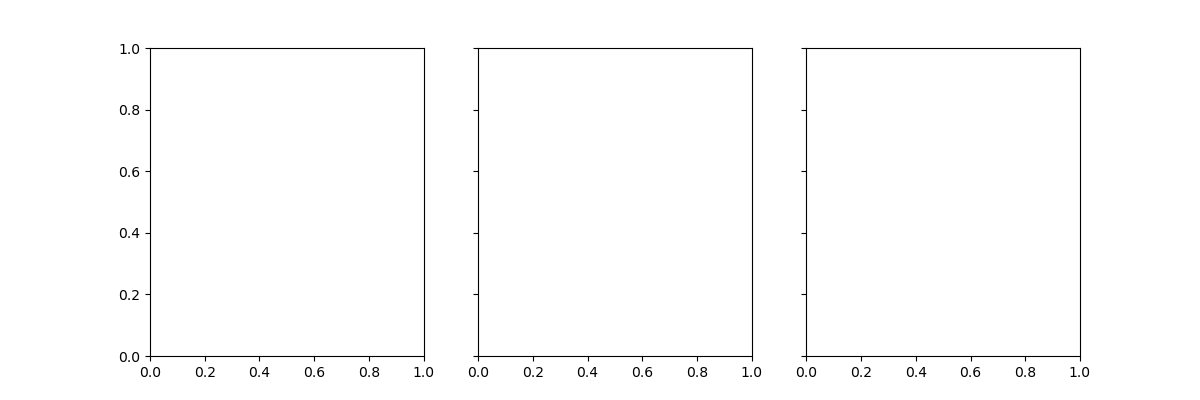

In [ ]:
base_folder =  '/sdf/data/lcls/ds/rix/'
proc_folder = './proc/'

bgrun = 86
runs=[112, 114]

exp = 'rix101231825'
tag = 'th80_tha440_photon'

fyaml = '../roi_input.yml'

bgname = f'{base_folder}/{exp}/hdf5/smalldata/run86_th80_tha440_photon/{exp}_Run0086.h5'
bgyaml = '../BGroi_input.yml'

avg = Average(runs, proc_path = 'proc/Run', avg = 'mean', output_path = f'avg/{runs[0]}_to_{runs[-1]}.h5',
             raw_path = f'{base_folder}/{exp}/hdf5/smalldata/' , bgpath = bgname, fyaml=fyaml, bgyaml=bgyaml, 
             save= True,norm = True)

print(avg.average.keys())

avg.plot_svls2D(figsize=(12,4),savefig=True)
avg.plot_svls1D(figsize=(12,4))

(28930, 8, 256)


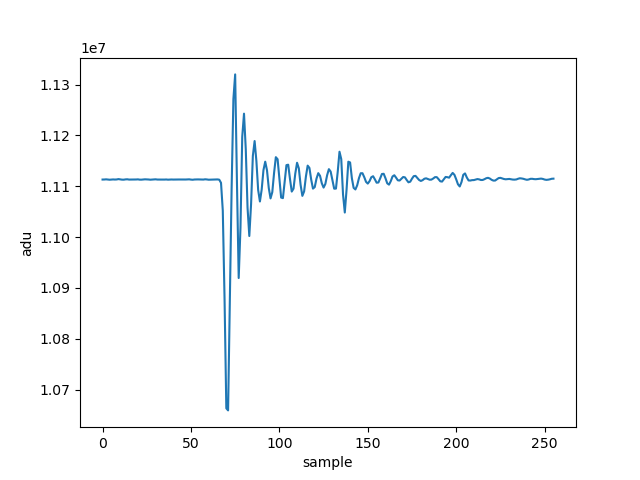

In [ ]:
import yaml
# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 120
fyaml_path = '../roi_input.yml'         # swap to ferufe/roi_input_ferufe.yml if needed
n_show     = -1                       # subsample for speed
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'

with open(fyaml_path) as f:
    cfg = yaml.safe_load(f)
    fim0_cfg = cfg['fim0']; fim1_cfg = cfg['fim1']

with h5py.File(fname, 'r') as h5:
    fim0_wf = h5['intg']['axis_svls']['det_rix_fim0_sum_full_area'][:n_show]
    fim1_wf = h5['intg']['axis_svls']['det_rix_fim1_sum_full_area'][:n_show]
    print(fim0_wf.shape)
    plt.figure()
    plt.plot(fim0_wf[1000][5])
    plt.xlabel('sample')
    plt.ylabel('adu')
    plt.show()